### Importación de librerías esenciales para EDA

In [13]:
# Importar librerías
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns
# Configurar estilo global para los gráficos
sns.set_theme(style="whitegrid")
plt.rcParams['figure.figsize'] = (10, 6)

print("¡Librerías importadas correctamente!")

¡Librerías importadas correctamente!


### Carga del Dataset e Inspección Inicial

In [14]:
# Cargar dataset
df = pd.read_csv('../data/raw/cell2celltrain.csv')

# Visualizar las primeras 5 filas para verificar la estructura
df.head()

,CustomerID,Churn,MonthlyRevenue,MonthlyMinutes,TotalRecurringCharge,DirectorAssistedCalls,OverageMinutes,RoamingCalls,PercChangeMinutes,PercChangeRevenues,...,ReferralsMadeBySubscriber,IncomeGroup,OwnsMotorcycle,AdjustmentsToCreditRating,HandsetPrice,MadeCallToRetentionTeam,CreditRating,PrizmCode,Occupation,MaritalStatus
0,3000002,Yes,24.00,219.0,22.0,0.25,0.0,0.0,-157.0,-19.0,...,0,4,No,0,30,Yes,1-Highest,Suburban,Professional,No
1,3000010,Yes,16.99,10.0,17.0,0.00,0.0,0.0,-4.0,0.0,...,0,5,No,0,30,No,4-Medium,Suburban,Professional,Yes
2,3000014,No,38.00,8.0,38.0,0.00,0.0,0.0,-2.0,0.0,...,0,6,No,0,Unknown,No,3-Good,Town,Crafts,Yes
3,3000022,No,82.28,1312.0,75.0,1.24,0.0,0.0,157.0,8.1,...,0,6,No,0,10,No,4-Medium,Other,Other,No
4,3000026,Yes,17.14,0.0,17.0,0.00,0.0,0.0,0.0,-0.2,...,0,9,No,1,10,No,1-Highest,Other,Professional,Yes


In [18]:
# Visualizar las últimas 5 filas
df.tail()

,CustomerID,Churn,MonthlyRevenue,MonthlyMinutes,TotalRecurringCharge,DirectorAssistedCalls,OverageMinutes,RoamingCalls,PercChangeMinutes,PercChangeRevenues,...,ReferralsMadeBySubscriber,IncomeGroup,OwnsMotorcycle,AdjustmentsToCreditRating,HandsetPrice,MadeCallToRetentionTeam,CreditRating,PrizmCode,Occupation,MaritalStatus
51042,3399958,Yes,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,...,0,6,No,0,60,No,1-Highest,Suburban,Other,Yes
51043,3399974,No,95.17,1745.0,85.0,0.99,45.0,4.7,122.0,15.9,...,0,9,No,1,60,No,3-Good,Other,Other,No
51044,3399978,Yes,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,...,0,7,No,1,80,No,5-Low,Other,Clerical,No
51045,3399990,No,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,...,0,9,No,0,30,No,5-Low,Other,Other,No
51046,3399994,No,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,...,0,0,No,1,60,Yes,5-Low,Other,Other,Unknown


### Auditoría de Estructura y Valores Nulos

In [4]:
# Radiografía general del DataFrame (tipos de datos y memoria)
df.info()

# Resumen de valores nulos y sus porcentajes
datos_faltantes = pd.DataFrame({
    'Total_Nulos': df.isnull().sum(),
    'Porcentaje_Nulos': (df.isnull().sum() / len(df)) * 100
})
print("\n--- Columnas con valores nulos ---")
print(datos_faltantes[datos_faltantes['Total_Nulos'] > 0])

<class 'pandas.DataFrame'>
RangeIndex: 51047 entries, 0 to 51046
Data columns (total 58 columns):
 #   Column                     Non-Null Count  Dtype  
---  ------                     --------------  -----  
 0   CustomerID                 51047 non-null  int64  
 1   Churn                      51047 non-null  str    
 2   MonthlyRevenue             50891 non-null  float64
 3   MonthlyMinutes             50891 non-null  float64
 4   TotalRecurringCharge       50891 non-null  float64
 5   DirectorAssistedCalls      50891 non-null  float64
 6   OverageMinutes             50891 non-null  float64
 7   RoamingCalls               50891 non-null  float64
 8   PercChangeMinutes          50680 non-null  float64
 9   PercChangeRevenues         50680 non-null  float64
 10  DroppedCalls               51047 non-null  float64
 11  BlockedCalls               51047 non-null  float64
 12  UnansweredCalls            51047 non-null  float64
 13  CustomerCareCalls          51047 non-null  float64
 14  T

### Análisis de la Variable Objetivo (Churn)

In [5]:
# Conteo absoluto y porcentual del desbalance de clases
conteo_abandono = df['Churn'].value_counts()
porcentaje_abandono = df['Churn'].value_counts(normalize=True) * 100

resumen_abandono = pd.DataFrame({
    'Cantidad': conteo_abandono,
    'Porcentaje (%)': porcentaje_abandono
})

print("--- Distribución de la Fuga de Clientes (Churn) ---")
print(resumen_abandono)

--- Distribución de la Fuga de Clientes (Churn) ---
       Cantidad  Porcentaje (%)
Churn                          
No        36336        71.18146
Yes       14711        28.81854


### Análisis Univariado

--- Estadísticas de MonthlyRevenue ---
count    50891.000000
mean        58.834492
std         44.507336
min         -6.170000
25%         33.610000
50%         48.460000
75%         71.065000
max       1223.380000
Name: MonthlyRevenue, dtype: float64


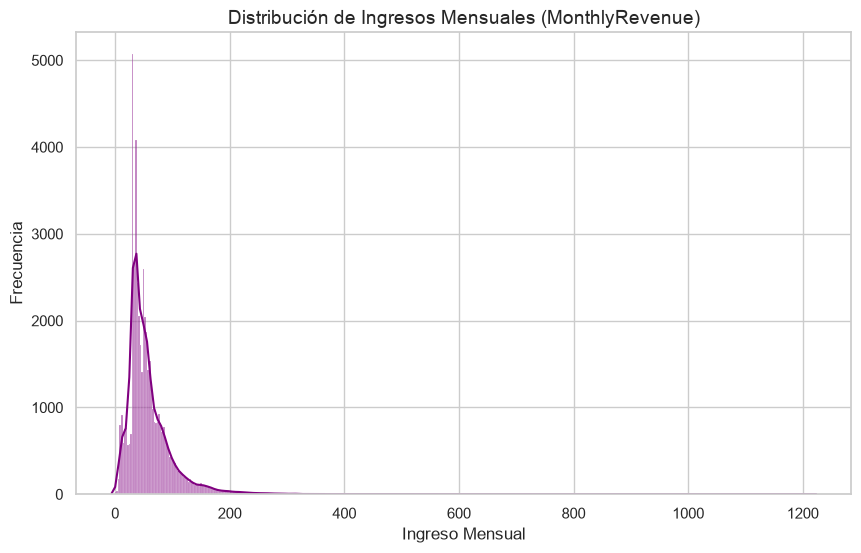

In [6]:
# Estadísticas descriptivas de los ingresos mensuales
print("--- Estadísticas de MonthlyRevenue ---")
print(df['MonthlyRevenue'].describe())

# Visualización de la distribución
sns.histplot(df['MonthlyRevenue'].dropna(), kde=True, color='purple')
plt.title('Distribución de Ingresos Mensuales (MonthlyRevenue)', fontsize=14)
plt.xlabel('Ingreso Mensual', fontsize=12)
plt.ylabel('Frecuencia', fontsize=12)
plt.show()

### Tratamiento de Duplicados e Imputación de Nulos

In [7]:
# 1. Eliminar filas duplicadas si las hay
print(f"Filas antes de limpiar duplicados: {df.shape[0]}")
df = df.drop_duplicates()
print(f"Filas después de limpiar duplicados: {df.shape[0]}")

# 2. Imputación de valores nulos (Actualizado para Pandas moderno)
# Numéricas con la mediana
for col in df.select_dtypes(include=['float64', 'int64']).columns:
    if df[col].isnull().sum() > 0:
        df[col] = df[col].fillna(df[col].median())

# Categóricas/Texto con la moda (aquí usamos 'object' y 'str')
for col in df.select_dtypes(include=['object', 'str']).columns:
    if df[col].isnull().sum() > 0:
        df[col] = df[col].fillna(df[col].mode()[0])

print("¡Limpieza de nulos completada con éxito y sin advertencias!")

Filas antes de limpiar duplicados: 51047
Filas después de limpiar duplicados: 51047
¡Limpieza de nulos completada con éxito y sin advertencias!


### Análisis Bivariado

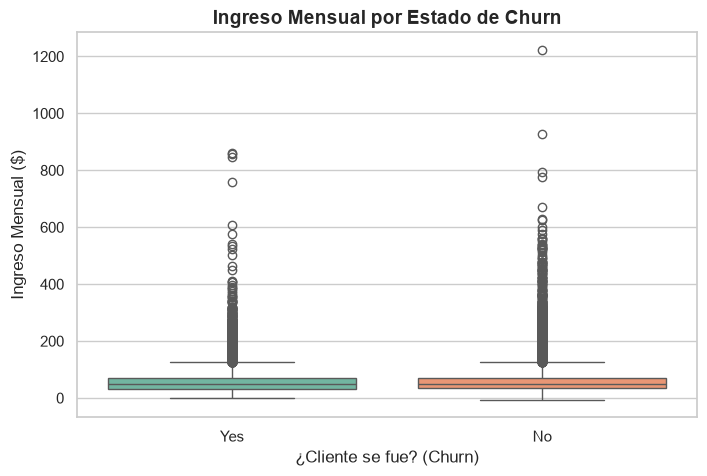

In [8]:
# Gráfico de caja (Boxplot) actualizado sin advertencias
plt.figure(figsize=(8, 5))
sns.boxplot(x='Churn', y='MonthlyRevenue', data=df, hue='Churn', palette='Set2', legend=False)
plt.title('Ingreso Mensual por Estado de Churn', fontsize=14, fontweight='bold')
plt.xlabel('¿Cliente se fue? (Churn)', fontsize=12)
plt.ylabel('Ingreso Mensual ($)', fontsize=12)
plt.show()

### Exportación del Dataset Limpio

In [10]:
import os

# Crear la carpeta 'processed' si no existe
os.makedirs('../data/processed', exist_ok=True)

# Guardar el DataFrame limpio sin índice extra
df.to_csv('../data/processed/cell2cell_churn_clean.csv', index=False)

print("¡Dataset limpio exportado con éxito a data/processed/!")

¡Dataset limpio exportado con éxito a data/processed/!
